# Chapter 16 · Barriers, lookbacks and the Brownian bridge: interactive demos

Companion to Chapter 16 of the [MFE 230D lecture notes](https://gennaroalberto.github.io/mfe230d-derivatives/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/mfe230d-derivatives/blob/main/code/notebooks/16-barriers.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

Throughout, $S_t=S_0e^{X_t}$ with $X_t=\nu t+\sigma W_t$ under the risk-neutral measure, $\nu=r-y-\sigma^2/2$, and
the defaults are the course's test case $S_0=K=100$, $T=1$, $r=1\%$, $y=2\%$, $\sigma=20\%$.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/mfe230d-derivatives#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, FloatLogSlider, Dropdown

from mfe230d.barriers import (barrier_mc_samples, barrier_price, bgk_price, bridge_extreme,
                              discrete_barrier_price, knockout_density, log_density, log_drift)
from mfe230d.style import COBALT, GOLD, GREY, INK, use_style

GREEN = "#1BAF7A"
use_style()

## 1. The knock-out density by images

For a down barrier $B<S_0$, $b=\log(B/S_0)$, the density of $X_T$ on the paths that never reach $b$ is the source
density $p_T(x)$ minus an image started at $2b$ with weight $e^{\lambda b}$, $\lambda=2\nu/\sigma^2$ (Theorem 16.1).
The left panel shows the construction. The right panel simulates $X_T$ exactly and decides survival in two ways:
continuously, by drawing the minimum of the Brownian bridge from $0$ to $X_T$ (Proposition 16.9), and at $m$ equally
spaced dates. The continuous survivors follow the image density, which vanishes at the barrier; the discretely
monitored ones do not.

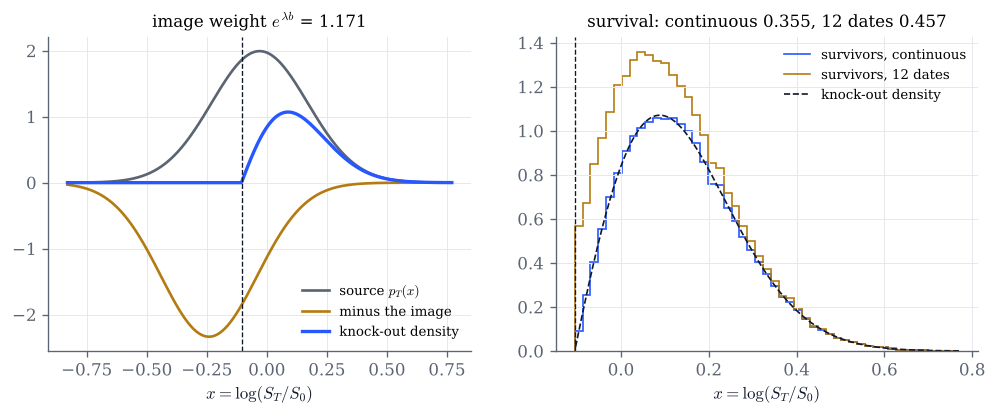

In [2]:
def images(B=90.0, sigma=0.2, r_minus_y=-0.01, T=1.0, m=12, n=200_000, seed=16):
    nu = r_minus_y - 0.5 * sigma**2
    b = np.log(B / 100.0)
    lam = 2 * nu / sigma**2
    s = sigma * np.sqrt(T)
    x = np.linspace(nu * T - 4 * s, nu * T + 4 * s, 600)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.plot(x, log_density(x, T, nu, sigma), color=GREY, label="source $p_T(x)$")
    ax.plot(x, -np.exp(lam * b) * log_density(x - 2 * b, T, nu, sigma), color=GOLD, label="minus the image")
    ax.plot(x, knockout_density(x, b, T, nu, sigma), color=COBALT, lw=2, label="knock-out density")
    ax.axvline(b, color=INK, ls="--", lw=0.8)
    ax.set(xlabel="$x=\\log(S_T/S_0)$", title=f"image weight $e^{{\\lambda b}}$ = {np.exp(lam * b):.3f}")
    ax.legend(fontsize=8)
    rng = np.random.default_rng(seed)
    n = int(n)
    Z = rng.standard_normal((n, m))
    paths = np.cumsum(nu * T / m + sigma * np.sqrt(T / m) * Z, axis=1)
    XT = paths[:, -1]
    mins = bridge_extreme(0.0, XT, sigma, T, 1.0 - rng.random(n), "min")
    bins = np.linspace(b, x[-1], 50)
    for sel, color, label in ((mins > b, COBALT, "survivors, continuous"), (paths.min(axis=1) > b, GOLD,
                              f"survivors, {m} dates")):
        h, e = np.histogram(XT[sel], bins=bins)
        ax2.stairs(h / (n * np.diff(e)), e, color=color, label=label)
    xs = x[x > b]
    ax2.plot(xs, knockout_density(xs, b, T, nu, sigma), color=INK, ls="--", lw=1, label="knock-out density")
    ax2.axvline(b, color=INK, ls="--", lw=0.8)
    p_surv = np.mean(mins > b)
    ax2.set(xlabel="$x=\\log(S_T/S_0)$", title=f"survival: continuous {p_surv:.3f}, {m} dates {np.mean(paths.min(axis=1) > b):.3f}")
    ax2.legend(fontsize=8)
    plt.show()

images()

In [3]:
# Explore: set r - y so that nu = 0 (image weight 1); move the barrier towards the spot; raise the number of dates.
interact(images,
         B=FloatSlider(value=90, min=70, max=99, step=1, continuous_update=False, description="barrier B"),
         sigma=FloatSlider(value=0.2, min=0.05, max=0.6, step=0.05, continuous_update=False, description="σ"),
         r_minus_y=FloatSlider(value=-0.01, min=-0.2, max=0.2, step=0.01, continuous_update=False, description="r − y"),
         T=FloatSlider(value=1.0, min=0.1, max=3.0, step=0.1, continuous_update=False, description="T"),
         m=IntSlider(value=12, min=1, max=252, continuous_update=False, description="dates m"),
         n=FloatLogSlider(value=2e5, base=10, min=4, max=6, step=0.25, continuous_update=False, description="paths"),
         seed=IntSlider(value=16, min=0, max=100, continuous_update=False, description="seed"));

## 2. Discrete monitoring and the continuity correction

The exact price of a barrier option monitored at $m$ equally spaced dates comes from the backward recursion of
Proposition 16.6 (Gauss-Legendre quadrature over the surviving region, one date at a time). The continuity correction of
Broadie, Glasserman and Kou (Proposition 16.7) prices it with the continuous formula and the barrier moved away from
the spot by the factor $e^{0.5826\,\sigma\sqrt{T/m}}$. The left panel shows the three prices against the barrier;
the right panel the corrected and the continuous prices minus the exact one.

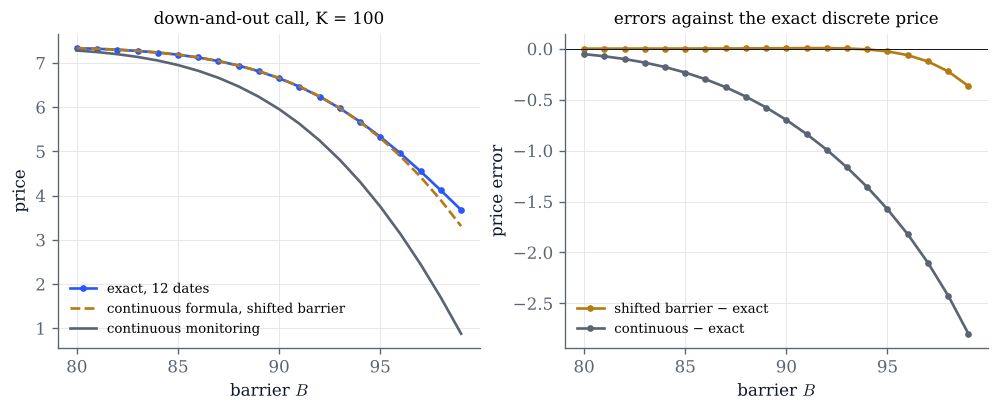

In [4]:
def discrete(kind="call", direction="down", m=12, sigma=0.2, K=100.0):
    TC = dict(T=1.0, r=0.01, y=0.02, sigma=sigma)
    barrier = f"{direction}-out"
    Bs = np.linspace(80, 99, 20) if direction == "down" else np.linspace(101, 130, 20)
    ex = np.array([discrete_barrier_price(100.0, K, B, **TC, m=m, kind=kind, barrier=barrier) for B in Bs])
    co = np.array([float(barrier_price(100.0, K, B, **TC, kind=kind, barrier=barrier)) for B in Bs])
    bg = np.array([float(bgk_price(100.0, K, B, **TC, m=m, kind=kind, barrier=barrier)) for B in Bs])
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.plot(Bs, ex, color=COBALT, marker="o", ms=3, label=f"exact, {m} dates")
    ax.plot(Bs, bg, color=GOLD, ls="--", label="continuous formula, shifted barrier")
    ax.plot(Bs, co, color=GREY, label="continuous monitoring")
    ax.set(xlabel="barrier $B$", ylabel="price", title=f"{direction}-and-out {kind}, K = {K:g}")
    ax.legend(fontsize=8)
    ax2.plot(Bs, bg - ex, color=GOLD, marker="o", ms=3, label="shifted barrier − exact")
    ax2.plot(Bs, co - ex, color=GREY, marker="o", ms=3, label="continuous − exact")
    ax2.axhline(0, color=INK, lw=0.6)
    ax2.set(xlabel="barrier $B$", ylabel="price error", title="errors against the exact discrete price")
    ax2.legend(fontsize=8)
    plt.show()

discrete()

In [5]:
# Explore: compare a down-and-out call with an up-and-out call; take m = 1, 4, 52, 252; raise sigma.
interact(discrete,
         kind=Dropdown(options=["call", "put"], value="call", description="payoff"),
         direction=Dropdown(options=["down", "up"], value="down", description="barrier"),
         m=IntSlider(value=12, min=1, max=252, continuous_update=False, description="dates m"),
         sigma=FloatSlider(value=0.2, min=0.05, max=0.5, step=0.05, continuous_update=False, description="σ"),
         K=FloatSlider(value=100, min=80, max=120, step=5, continuous_update=False, description="strike K"));

## 3. Simulating a continuous barrier: grid against bridge

To price a *continuously* monitored down-and-out call by simulation on $m$ time steps, one can check the barrier at
the grid dates only (biased: this prices the discretely monitored contract), weight each path by the probability
$\prod_j(1-p_j)$ that the Brownian bridges between the dates stay above the barrier, or draw the minimum of each
bridge exactly (Proposition 16.9). The left panel shows the estimates with $\pm2$ standard errors against the closed
form; the right panel the standard deviation per path, which is what decides the cost of a given accuracy.

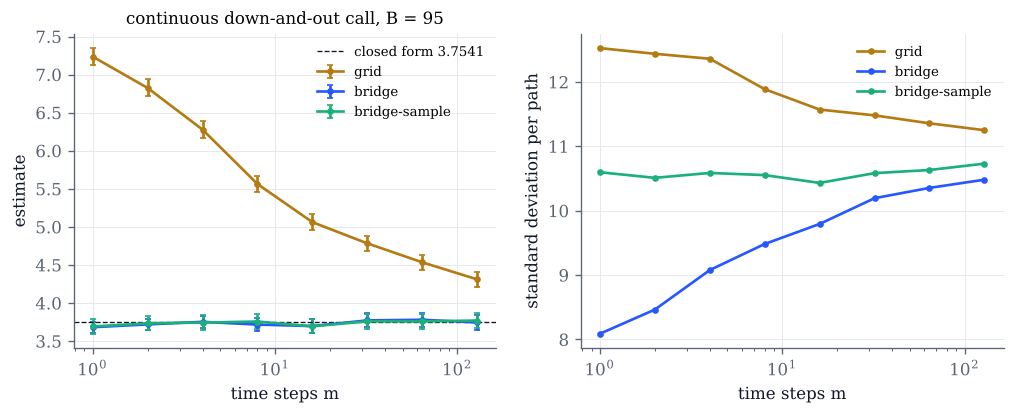

In [6]:
def bridge_demo(B=95.0, sigma=0.2, n=50_000, seed=1):
    TC = dict(T=1.0, r=0.01, y=0.02, sigma=sigma)
    exact = float(barrier_price(100.0, 100.0, B, **TC))
    ms = np.array([1, 2, 4, 8, 16, 32, 64, 128])
    n = int(n)
    res = {k: [] for k in ("grid", "bridge", "bridge-sample")}
    for i, m in enumerate(ms):
        rng = np.random.default_rng([seed, i])
        Z = rng.standard_normal((n, m))
        U = 1.0 - rng.random((n, m))
        for mon in res:
            x = barrier_mc_samples(100.0, 100.0, B, **TC, m=m, Z=Z, U=U, monitor=mon)
            res[mon].append((x.mean(), x.std(ddof=1)))
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    for mon, color in (("grid", GOLD), ("bridge", COBALT), ("bridge-sample", GREEN)):
        a = np.array(res[mon])
        ax.errorbar(ms, a[:, 0], yerr=2 * a[:, 1] / np.sqrt(n), color=color, marker="o", ms=3, capsize=2, label=mon)
        ax2.plot(ms, a[:, 1], color=color, marker="o", ms=3, label=mon)
    ax.axhline(exact, color=INK, ls="--", lw=0.8, label=f"closed form {exact:.4f}")
    ax.set(xscale="log", xlabel="time steps m", ylabel="estimate", title=f"continuous down-and-out call, B = {B:g}")
    ax.legend(fontsize=8)
    ax2.set(xscale="log", xlabel="time steps m", ylabel="standard deviation per path")
    ax2.legend(fontsize=8)
    plt.show()

bridge_demo()

In [7]:
# Explore: move the barrier close to the spot, where the grid bias is largest; change sigma.
interact(bridge_demo,
         B=FloatSlider(value=95, min=70, max=99, step=1, continuous_update=False, description="barrier B"),
         sigma=FloatSlider(value=0.2, min=0.05, max=0.5, step=0.05, continuous_update=False, description="σ"),
         n=FloatLogSlider(value=5e4, base=10, min=4, max=5.5, step=0.25, continuous_update=False, description="paths"),
         seed=IntSlider(value=1, min=0, max=100, continuous_update=False, description="seed"));

## Things to try

- In section 1, choose $r-y=\sigma^2/2$, so that $\nu=0$. What is the image weight, and why? Then take a large
  positive drift: what happens to the image, and to the probability of survival?
- In section 1, raise the number of dates from 1 to 252. How fast does the histogram of the discretely monitored
  survivors approach the knock-out density near the barrier?
- In section 2, put the barrier of a down-and-out call at 99 with $m=12$, then at 85. In which case does the shifted
  barrier work, and how does that match the discussion after Proposition 16.7?
- In section 3, with $B=99$, how many steps does grid monitoring need to bring the bias below two standard errors?
  Compare with the bridge estimators, and explain with Theorem 10.11 (conditional Monte Carlo) why the
  weighted estimator has its smallest variance at $m=1$.